# 🧠 BrainScan AI — 02. Analyse Exploratoire des Données (EDA)

---

### 📌 Contexte et Objectifs
L'Analyse Exploratoire des Données (**Exploratory Data Analysis - EDA**) est une étape capitale avant toute modélisation en Deep Learning médical. Elle permet de :
1. Valider la qualité et l'intégrité visuelle des coupes d'IRM cérébrales.
2. Analyser précisément la répartition des classes pathologiques et saines.
3. Quantifier l'éventuel déséquilibre de classes (*class imbalance*) susceptible de biaiser le réseau.
4. Calculer une stratégie de rééquilibrage mathématique (`class_weight`) pour pénaliser équitablement les erreurs d'apprentissage.
5. Étudier le profil spectrophotométrique et la distribution d'intensité lumineuse des pixels.


## 1. Importation des Outils d'Analyse et de Visualisation

### 💡 Ce que nous allons faire :
Nous importons les librairies graphiques spécialisées `matplotlib.pyplot` et `seaborn`, l'utilitaire de calcul de poids de classe de `scikit-learn`, et configurons une haute résolution de rendu graphique (`figure.dpi = 100`).

### ⚙️ Comment ça fonctionne et pourquoi :
* **`matplotlib.pyplot` & `seaborn`** : Offrent des capacités avancées de visualisation statistique (diagrammes à barres, camemberts, grilles d'images, histogrammes de densité KDE).
* **`compute_class_weight`** : Formule heuristique inversement proportionnelle aux fréquences des classes, permettant d'égaliser l'impact de chaque classe sur la fonction de perte.

### 🔍 Résultat attendu :
Environnement de traçage graphique configuré avec un thème soigné et un rendu net.


In [1]:
import os
import warnings

import cv2
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

## 2. Chargement des Tenseurs Prétraités

### 💡 Ce que nous allons faire :
Nous chargeons les tableaux `X_train`, `X_test`, `y_train`, `y_test` et `label_classes` générés lors de l'étape 01, puis nous convertissons les vecteurs One-Hot en étiquettes entières 1D (`y_train_int`, `y_test_int`) via `np.argmax`.

### ⚙️ Comment ça fonctionne et pourquoi :
`np.argmax(..., axis=1)` identifie l'indice de la colonne contenant la valeur maximale ($1$), ce qui permet de manipuler les classes sous forme scalaire pour les fonctions statistiques de comptage et de tracé.

### 🔍 Résultat attendu :
Affichage des dimensions confirmant 5 618 coupes d'entraînement, 1 405 coupes de test et les 4 classes identifiées (`glioma`, `meningioma`, `notumor`, `pituitary`).


In [2]:
DATA_DIR = "../data"
PROCESSED_DIR = "../data/processed"

X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"))
X_test = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"))
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))
y_test = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))
classes = np.load(os.path.join(PROCESSED_DIR, "label_classes.npy"), allow_pickle=True)

y_train_int = np.argmax(y_train, axis=1)
y_test_int = np.argmax(y_test, axis=1)

print(f"Train : {X_train.shape}, Test : {X_test.shape}")
print(f"Classes : {classes}")

Train : (5618, 224, 224, 3), Test : (1405, 224, 224, 3)
Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']


## 3. Analyse de la Distribution Globale des Classes

### 💡 Ce que nous allons faire :
Nous combinons les labels d'entraînement et de test pour analyser la répartition globale des 7 023 images sous forme d'un double graphique : un diagramme en barres avec comptage absolu et un camembert de répartition en pourcentages.

### ⚙️ Comment ça fonctionne et pourquoi :
Cette vue macroscopique permet de déceler d'un coup d'œil si une classe domine excessivement le dataset (ce qui amènerait un réseau naïf à toujours prédire la classe majoritaire).

### 🔍 Résultat attendu :
Affichage d'une figure sauvegardée dans `data/processed/class_distribution.png` montrant les effectifs réels :
* `notumor` : ~2 000 images (~28.5%)
* `pituitary` : ~1 757 images (~25.0%)
* `meningioma` : ~1 645 images (~23.4%)
* `glioma` : ~1 621 images (~23.1%)


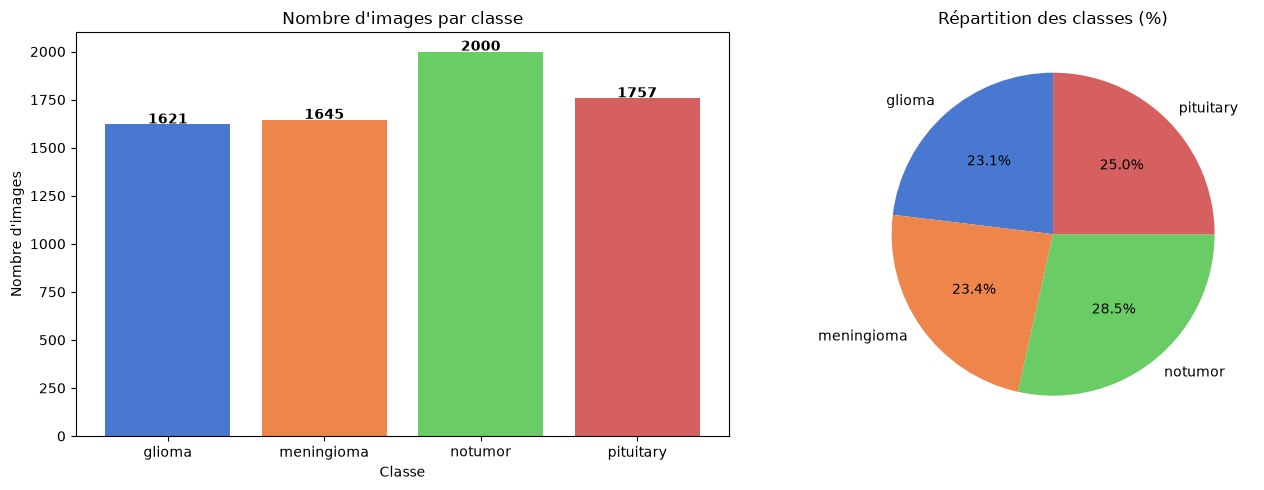

In [3]:
all_labels = np.concatenate([y_train_int, y_test_int])
unique, counts = np.unique(all_labels, return_counts=True)
class_names = classes[unique]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(class_names, counts, color=sns.color_palette("muted", len(classes)))
axes[0].set_title("Nombre d'images par classe")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Nombre d'images")
for i, v in enumerate(counts):
    axes[0].text(i, v + 5, str(v), ha="center", fontweight="bold")

axes[1].pie(counts, labels=class_names, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("muted", len(classes)))
axes[1].set_title("Répartition des classes (%)")

plt.tight_layout()
plt.savefig(os.path.join(PROCESSED_DIR, "class_distribution.png"), bbox_inches="tight")
plt.show()

## 4. Galerie d'Échantillons d'IRM par Classe Pathologique

### 💡 Ce que nous allons faire :
Nous générons une grille visuelle présentant 4 échantillons d'images IRM tirés aléatoirement pour chacune des 4 classes (soit une matrice 4 × 4 = 16 coupes médicales).

### ⚙️ Comment ça fonctionne et pourquoi :
L'inspection visuelle directe par un praticien ou data scientist est fondamentale :
* Vérifier le contraste anatomique entre tissu sain et tissu tumoral.
* Observer la localisation caractéristique : les gliomes (infiltrants dans la substance blanche/grise), les méningiomes (extra-axiaux sur les méninges périphériques), et les adénomes hypophysaires (centrés sur la selle turcique).
* S'assurer de l'absence d'artefacts d'acquisition ou de redimensionnement anormal.

### 🔍 Résultat attendu :
Affichage d'une grille nette sauvegardée dans `data/processed/sample_images.png`, confirmant la qualité clinique des coupes axiales/coronales.


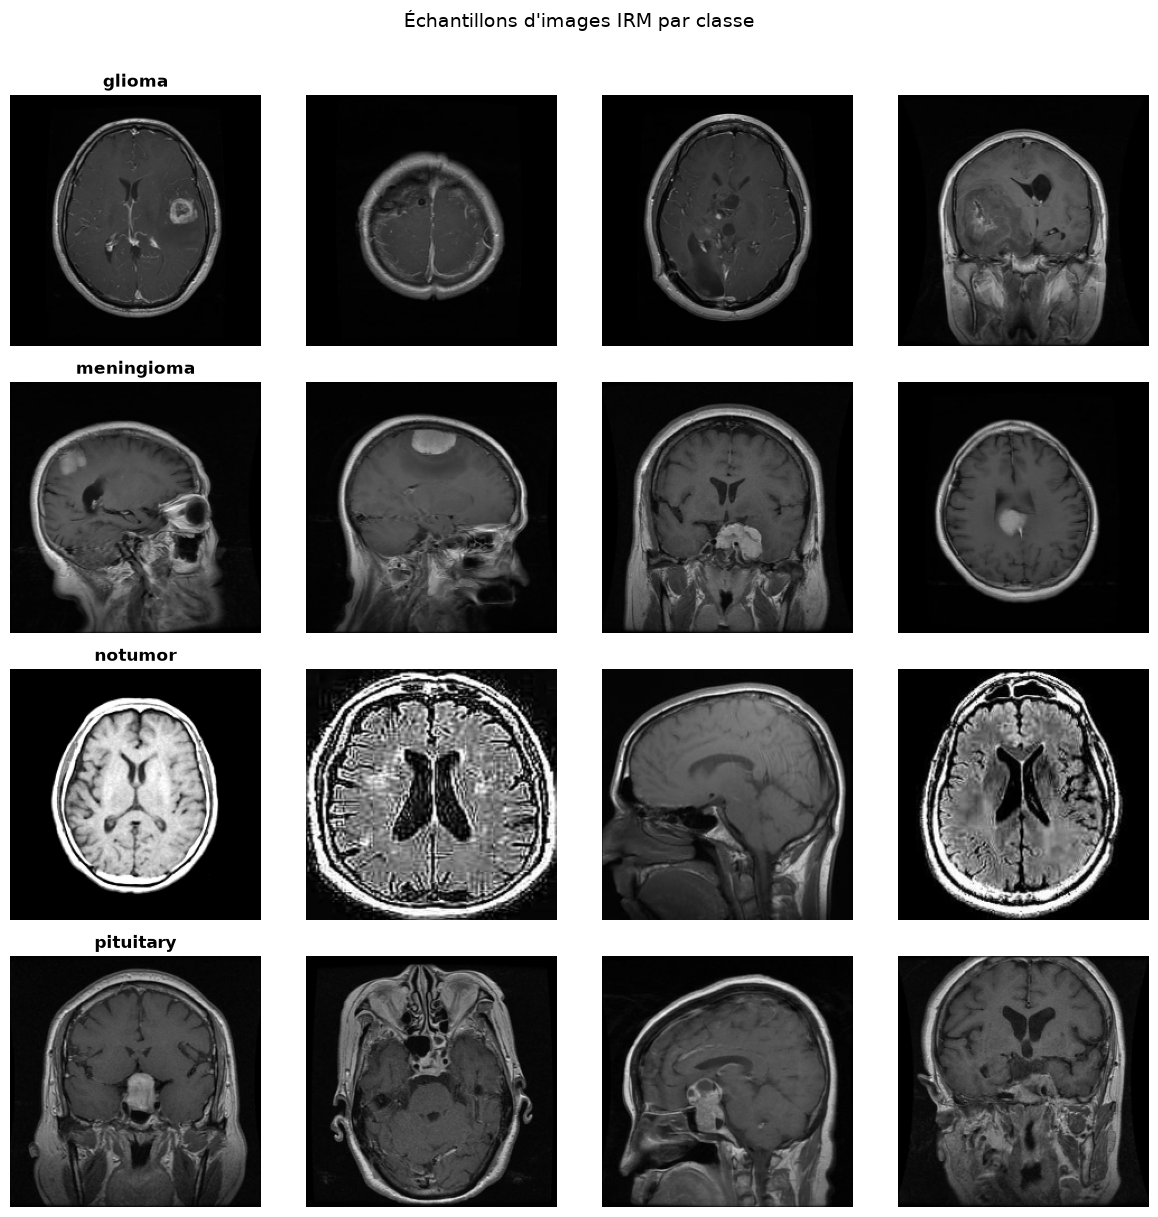

In [4]:
N_SAMPLES = 4
fig, axes = plt.subplots(len(classes), N_SAMPLES, figsize=(N_SAMPLES * 3, len(classes) * 3))

for row, cls_idx in enumerate(unique):
    cls_name = classes[cls_idx]
    cls_images = X_train[y_train_int == cls_idx]
    sample_indices = np.random.choice(len(cls_images), size=min(N_SAMPLES, len(cls_images)), replace=False)

    for col, idx in enumerate(sample_indices):
        axes[row, col].imshow(cls_images[idx])
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(cls_name, fontsize=12, fontweight="bold")

plt.suptitle("Échantillons d'images IRM par classe", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(PROCESSED_DIR, "sample_images.png"), bbox_inches="tight")
plt.show()

## 5. Évaluation Numérique du Déséquilibre des Classes

### 💡 Ce que nous allons faire :
Nous mesurons les fréquences individuelles de chaque classe dans le jeu d'entraînement et calculons le ratio de déséquilibre : $\text{Ratio} = \frac{\text{Classe max}}{\text{Classe min}}$.

### ⚙️ Comment ça fonctionne et pourquoi :
* Si le ratio est supérieur à $2.0$, le déséquilibre est qualifié de modéré à fort et nécessite obligatoirement des mécanismes compensatoires.
* Dans notre dataset, le ratio est d'environ $1.23$, ce qui indique un dataset globalement sain et équilibré, avec toutefois une légère prédominance des cas sains (`notumor`).

### 🔍 Résultat attendu :
Affichage des comptages exacts par classe et confirmation que le déséquilibre reste léger ($< 2.0$), garantissant une base d'apprentissage saine.


In [5]:
train_counts = np.bincount(y_train_int)
imbalance_ratio = train_counts.max() / train_counts.min()

print("Distribution dans le jeu d'entraînement :")
for i, cnt in enumerate(train_counts):
    print(f"  {classes[i]}: {cnt} images")

print(f"\nRatio de déséquilibre (max/min) : {imbalance_ratio:.2f}")

if imbalance_ratio > 2.0:
    print("⚠️  Déséquilibre détecté — class_weight sera appliqué à l'entraînement.")
else:
    print("✅  Classes relativement équilibrées.")

Distribution dans le jeu d'entraînement :
  glioma: 1297 images
  meningioma: 1316 images
  notumor: 1600 images
  pituitary: 1405 images

Ratio de déséquilibre (max/min) : 1.23
✅  Classes relativement équilibrées.


## 6. Calcul des Poids de Classes Équilibrés (`class_weight`)

### 💡 Ce que nous allons faire :
Nous calculons les coefficients de pondération équilibrés via la fonction `compute_class_weight` de Scikit-Learn et les enregistrons dans `data/processed/class_weights.npy`.

### ⚙️ Comment ça fonctionne et pourquoi :
La formule utilisée est :
$$w_j = \frac{N}{K \times n_j}$$
où $N$ est le nombre total d'échantillons, $K$ le nombre de classes, et $n_j$ le nombre d'échantillons de la classe $j$.
* Les classes légèrement moins nombreuses reçoivent un poids légèrement supérieur à $1.0$, pénalisant plus lourdement les erreurs du modèle sur ces classes.
* Ces poids seront injectés directement dans l'argument `class_weight` de `model.fit()` lors de l'entraînement.

### 🔍 Résultat attendu :
Calcul précis des poids pour chaque classe (autour de $1.0 \pm 0.15$) et sauvegarde du fichier `class_weights.npy`.


In [6]:
cw = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(classes)),
    y=y_train_int
)
class_weight_dict = dict(enumerate(cw))

print("Poids par classe :")
for idx, weight in class_weight_dict.items():
    print(f"  {classes[idx]}: {weight:.4f}")

np.save(os.path.join(PROCESSED_DIR, "class_weights.npy"), cw)

Poids par classe :
  glioma: 1.0829
  meningioma: 1.0672
  notumor: 0.8778
  pituitary: 0.9996


## 7. Analyse du Profil de Distribution des Intensités de Pixels

### 💡 Ce que nous allons faire :
Nous traçons les histogrammes et courbes de densité d'intensité des pixels pour chaque classe dans l'espace normalisé $[0, 1]$.

### ⚙️ Comment ça fonctionne et pourquoi :
En IRM cérébrale, l'intensité dépend de la séquence d'acquisition (T1, T2, FLAIR) et de la densité protonique des tissus :
* Le pic prononcé vers $0.0$ correspond au fond noir de l'image (air autour du crâne).
* Les intensités intermédiaires ($0.2$ à $0.6$) correspondent à la matière grise, la matière blanche et le liquide céphalo-rachidien.
* Les intensités élevées ($> 0.7$) révèlent souvent des zones d'hyper-signal caractéristiques de calcifications, de rehaussements tumoraux après injection de produit de contraste, ou d'œdèmes péritumoraux.

### 🔍 Résultat attendu :
Affichage de 4 histogrammes sauvegardés dans `data/processed/pixel_distribution.png` montrant des signatures spectrophotométriques cohérentes et stables.


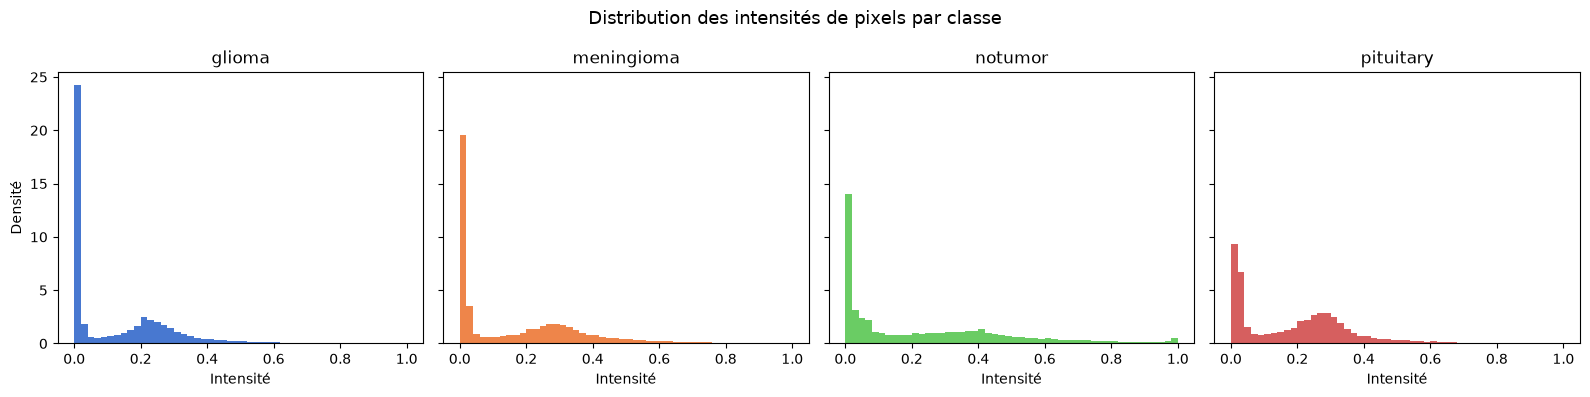

In [7]:
fig, axes = plt.subplots(1, len(classes), figsize=(16, 4), sharey=True)

for i, cls_idx in enumerate(unique):
    cls_pixels = X_train[y_train_int == cls_idx].flatten()
    axes[i].hist(cls_pixels, bins=50, color=sns.color_palette("muted")[i], edgecolor="none", density=True)
    axes[i].set_title(classes[cls_idx])
    axes[i].set_xlabel("Intensité")
    if i == 0:
        axes[i].set_ylabel("Densité")

plt.suptitle("Distribution des intensités de pixels par classe", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(PROCESSED_DIR, "pixel_distribution.png"), bbox_inches="tight")
plt.show()

## 8. 📋 Synthèse et Conclusion de l'Analyse Exploratoire (EDA)

---

### ✅ Bilan des observations :
1. **Équilibre des données** : Le dataset présente une excellente représentativité avec un ratio de déséquilibre faible ($1.23$). Toutes les 4 classes disposent de plus de 1 600 images chacune.
2. **Qualité visuelle** : Les coupes d'IRM après redimensionnement $224 \times 224$ préservent parfaitement les détails anatomiques et les contours tumoraux nécessaires à la détection par convolution.
3. **Stratégie de pondération** : Les `class_weights` sont calculés et prêts à être injectés dans la fonction de perte pour neutraliser tout biais résiduel en faveur de la classe saine.
4. **Cohérence radiologique** : Les distributions d'intensité confirment la standardisation du contraste sans saturation anormale.

### ➡️ Prochaine étape :
Le notebook `03_model_training.ipynb` construira l'architecture du réseau de neurones convolutif (**CNN**) BrainScan, configurera l'optimiseur Adam, les callbacks d'arrêt précoce (*EarlyStopping*), et effectuera l'entraînement avec traçabilité complète sous **MLflow**.
